# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

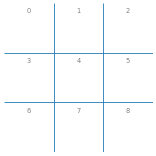


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [3]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

**[Bài 2] Nhận xét `results()`.** Hàm đặt quân của người chơi vào ô `action`, rồi trả về **danh sách mọi bàn có thể xảy ra
sau đó**, mỗi bàn ứng với một cách đáp trả của đối thủ. Ví dụ trên: x đi ô 4 trên bàn trống cho ra **8 trạng thái**, ứng với 8 ô
o có thể đi. Nếu bàn đã đầy sau nước của người chơi thì chỉ trả về chính bàn đó. Như vậy đối thủ được coi là một phần của môi
trường, và hành động của người chơi có kết quả **không xác định** (nondeterministic).

### Recursive AND-OR Search (DFS)

In [4]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

### [Bài 2] Cách hoạt động của `and_or_search()`, `or_search()`, `and_search()`

- **`and_or_search(state, player, draw_is_win)`**: đặt lại bộ đếm `COUNT`, gọi `or_search` và trả về **kế hoạch có điều kiện**
  (hoặc `None` nếu không có). `draw_is_win = True` nghĩa là chấp nhận hòa là đạt mục tiêu; `False` là chỉ chấp nhận thắng.
- **`or_search` (nút OR: lượt của mình)**: nếu đã thua (hoặc hòa khi không chấp nhận hòa) thì thất bại. Ngược lại thử **lần lượt từng
  nước theo thứ tự chỉ số ô**; với mỗi nước, gọi `and_search` trên mọi kết quả có thể. Trả `[nước đi, kế hoạch con]` cho **nước đầu
  tiên** thành công, hoặc `None` nếu không nước nào thành công. Chỉ cần **một** nước tốt.
- **`and_search` (nút AND: mọi cách đáp trả của đối thủ)**: **mọi** trạng thái kết quả đều phải thành công. Gặp trạng thái thắng thì
  trả `"win"`, hòa (khi chấp nhận) thì trả `"draw"`, còn lại gọi `or_search`; chỉ cần **một** nhánh thất bại là bỏ cả nhánh (`None`).
  Trả về trạng thái thắng ngay lập tức là đúng, vì nếu một kết quả đã thắng thì chính nước của mình đã tạo ra 3 quân thẳng hàng.
- **Dạng kế hoạch:** `[nước đi, [['if', bàn sau khi đối thủ đáp, 'then', kế hoạch tiếp], ...]]`, kết thúc bằng `'win'` hoặc `'draw'`.
  Đọc là: "đi ô này; nếu đối thủ đi thế này thì làm tiếp thế kia".

# Some Tests

## x is about to win

Board:


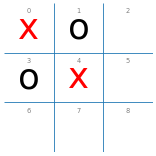


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: total: 15.6 ms
Wall time: 3 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [6]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: total: 0 ns
Wall time: 5.36 ms


**[Bài 2] Nhận xét test "x sắp thắng".** Cả hai chế độ đều chọn **ô 2**, không chọn ô 8 (thắng ngay).
- **Vì sao chọn 2 mà không chọn 8?** `or_search` thử các ô trống theo thứ tự chỉ số **2, 5, 6, 7, 8** và dừng ở **nước đầu tiên** có kế
  hoạch thành công. Sau khi đi ô 2, x có **hai đường đe dọa** cùng lúc (2-4-6 thiếu ô 6, 0-4-8 thiếu ô 8), o chỉ chặn được
  một nên x vẫn chắc thắng; vì thế ô 2
  được nhận trước khi ô 8 kịp được thử. AND-OR tìm *một* kế hoạch đạt mục tiêu, **không tìm kế hoạch nhanh nhất**.
- **Kế hoạch khi chấp nhận hòa (22 nút):** có nhánh không thắng dù thắng được. Ví dụ o đáp ô 6: x đáng lẽ đi ô 8 để thắng ngay
  (0-4-8), nhưng kế hoạch chọn ô 5 vì ô 5 được thử trước và vẫn bảo đảm "thắng hoặc hòa"; trong nhánh này còn một lá `'draw'`.
- **Kế hoạch chỉ thắng (30 nút):** mọi lá đều là `'win'`; cũng nhánh o đáp ô 6, kế hoạch đi ô 8 và thắng ngay. Mục tiêu khắt khe
  hơn nên phải duyệt nhiều nút hơn (30 so với 22).

## x can draw_is_win if it chooses 7

Board:


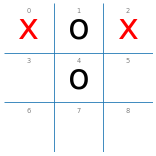


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: total: 0 ns
Wall time: 4.12 ms


In [7]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [8]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: total: 0 ns
Wall time: 4.41 ms


**[Bài 2] Nhận xét test "x hòa được nếu đi 7".**
- **Thắng hoặc hòa:** kế hoạch bắt đầu bằng **ô 7** (64 nút). Các ô 3, 5, 6 được thử trước nhưng thất bại vì o đang có 1 và 4
  trên cột giữa, không chặn ở 7 thì o thắng. Kế hoạch sau đó liệt kê cách đáp cho từng nước của o, ví dụ o đi 5 thì x đi 3,
  o đi 3 thì x đi 5, và mọi nhánh kết thúc bằng `'win'` hoặc `'draw'`.
- **Chỉ thắng:** trả `None` (69 nút): **không có nước nào bảo đảm thắng**. Lúc này AND-OR không cho biết nước nào "ít tệ nhất",
  dù ô 7 vẫn giữ được hòa. Đây là hạn chế của cách trả lời có/không.

## a bad situation

Board:


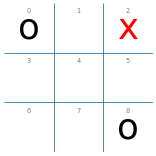


Win or draw:
Number of nodes searched: 155


None

CPU times: total: 15.6 ms
Wall time: 5.48 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

**[Bài 2] Nhận xét test "thế xấu".** Kế hoạch là `None` ngay cả khi chấp nhận hòa (155 nút): **x không thể bảo đảm hòa**.
o có 0 và 8 nên x buộc phải chặn ở ô 4; o đáp ô 6 tạo hai đe dọa cùng lúc (0-3-6 và 6-7-8), x chỉ chặn được một. Mọi nước của
x đều dẫn tới một nhánh thua, nên mọi nút AND đều thất bại.

## Empty board: Only a draw_is_win can be guaranteed

Board:


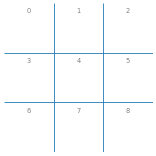


Win or draw:
Number of nodes searched: 966


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: total: 46.9 ms
Wall time: 52.3 ms


In [10]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [11]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 16213


None

CPU times: total: 375 ms
Wall time: 382 ms


**[Bài 2] Nhận xét test "bàn trống".**
- **Thắng hoặc hòa:** có kế hoạch, bắt đầu bằng **ô 0** (966 nút): ô 0 là ô đầu tiên được thử và đã bảo đảm ít nhất hòa.
- **Chỉ thắng:** `None` sau **16.213 nút**: từ bàn trống **không có cách bảo đảm thắng**, đúng với kết quả Minimax (giá trị 0, Bài 3).
  Phải duyệt nhiều hơn khoảng 17 lần vì để kết luận "không có kế hoạch", thuật toán phải chứng minh **mọi** nước đầu đều thất bại,
  thay vì dừng ở nước đầu tiên thành công.

### [Bài 2] Bảng tổng hợp 4 test case

Chạy lại 4 trạng thái trên với cả hai mục tiêu, ghi: có kế hoạch không, nước đi đầu tiên, số nút và thời gian.

In [12]:
# [Bài 2] Bảng tổng hợp 4 test case, mỗi case chạy với draw_is_win = True (thắng hoặc hòa) và False (chỉ thắng).
import time
import pandas as pd

def board_from(xs=(), os=()):
    b = empty_board()
    for i in xs: b[i] = 'x'
    for i in os: b[i] = 'o'
    return b

CASES = {
    'x sắp thắng':        board_from(xs=(0, 4), os=(1, 3)),
    'x hòa được nếu đi 7': board_from(xs=(0, 2), os=(1, 4)),
    'thế xấu':            board_from(xs=(2,), os=(0, 8)),
    'bàn trống':          board_from(),
}

old_debug, DEBUG = DEBUG, 0
rows = []
for name, board in CASES.items():
    for draw_is_win in (True, False):
        start = time.perf_counter()
        plan = and_or_search(board, player='x', draw_is_win=draw_is_win)
        ms = (time.perf_counter() - start) * 1000
        rows.append({'trạng thái': name,
                     'mục tiêu': 'thắng hoặc hòa' if draw_is_win else 'chỉ thắng',
                     'có kế hoạch?': plan is not None,
                     'nước đi đầu tiên': plan[0] if plan is not None else '–',
                     'số nút': COUNT, 'thời gian (ms)': round(ms, 2)})
DEBUG = old_debug
and_or_table = pd.DataFrame(rows)
and_or_table

,trạng thái,mục tiêu,có kế hoạch?,nước đi đầu tiên,số nút,thời gian (ms)
0,x sắp thắng,thắng hoặc hòa,True,2,22,0.68
1,x sắp thắng,chỉ thắng,True,2,30,0.80
2,x hòa được nếu đi 7,thắng hoặc hòa,True,7,64,1.61
3,x hòa được nếu đi 7,chỉ thắng,False,–,69,1.30
4,thế xấu,thắng hoặc hòa,False,–,155,3.83
5,thế xấu,chỉ thắng,False,–,147,3.84
6,bàn trống,thắng hoặc hòa,True,0,966,27.75
7,bàn trống,chỉ thắng,False,–,16213,397.77


**[Bài 2] Nhận xét bảng.**
- AND-OR trả lời câu hỏi **có/không**: có kế hoạch bảo đảm mục tiêu hay không. Khi có, nó dừng ngay ở nước đầu tiên thành công nên
  duyệt rất ít nút: **966 nút** cho bàn trống (thắng hoặc hòa), so với **549.946 nút** của Minimax và **18.297 nút** của Alpha-Beta
  trên cùng bàn (Bài 3).
- Khi **không có** kế hoạch, thuật toán phải thử hết mọi nước nên tốn hơn nhiều: bàn trống ở chế độ chỉ thắng cần 16.213 nút.
- Kết luận về giá trị khớp với Minimax: x sắp thắng → thắng; x hòa được → chỉ hòa; thế xấu → không giữ được hòa; bàn trống → hòa.
- Thời gian (ms) thay đổi theo máy; số nút cố định giữa các lần chạy.

## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [13]:
# [Bài 2] and_or_player gọi np.random.choice khi không có kế hoạch, nhưng notebook gốc chưa import numpy
# (dễ gặp NameError: name 'np' is not defined). Import trước khi chạy phần Experiments.
import numpy as np

In [14]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


print("and-or-search vs. random:")
%time display(play(and_or_player, random_player))

print()
print("random vs. and-or-search")
%time display(play(random_player, and_or_player))

and-or-search vs. random:


{'x': 94, 'o': 0, 'd': 6}

CPU times: total: 3.16 s
Wall time: 3.17 s

random vs. and-or-search


{'x': 0, 'o': 69, 'd': 31}

CPU times: total: 4.42 s
Wall time: 4.49 s


**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

**[Bài 2] Nhận xét ô gốc AND-OR đấu Random.** Ô gốc chạy 100 ván mỗi vai nhưng **không cố định seed**, nên số liệu khác nhau
mỗi lần chạy. Ô gốc cũng chậm (vài giây cho 100 ván) vì agent **lập lại toàn bộ kế hoạch ở mỗi nước** thay vì lưu kế hoạch và
đi theo. Ô dưới chạy lại với seed 42 và đo thời gian trung bình mỗi nước của AND-OR.

In [15]:
# [Bài 2] AND-OR đấu Random 100 ván (seed 42) ở cả hai vai, có thời gian trung bình mỗi nước của AND-OR.
def measured(agent, times):
    """Bọc agent để đo thời gian từng nước đi."""
    def wrapped(board, player='x'):
        start = time.perf_counter()
        move = agent(board, player)
        times.append(time.perf_counter() - start)
        return move
    return wrapped

DEBUG = 0
rows = []
for role in ('x', 'o'):
    np.random.seed(42)
    times = []
    agent = measured(and_or_player, times)
    res = play(agent, random_player, N=100) if role == 'x' else play(random_player, agent, N=100)
    other_role = 'o' if role == 'x' else 'x'
    rows.append({'AND-OR cầm': role + (' (đi trước)' if role == 'x' else ' (đi sau)'), 'số ván': 100,
                 'thắng': res[role], 'hòa': res['d'], 'thua': res[other_role],
                 'TG TB/nước (ms)': round(1000 * float(np.mean(times)), 2)})
and_or_vs_random = pd.DataFrame(rows)
and_or_vs_random

,AND-OR cầm,số ván,thắng,hòa,thua,TG TB/nước (ms)
0,x (đi trước),100,96,4,0,9.12
1,o (đi sau),100,77,23,0,12.12


**[Bài 2] Nhận xét AND-OR đấu Random (100 ván, seed 42).**
- **Cầm x (đi trước): thắng 96, hòa 4, thua 0. Cầm o (đi sau): thắng 77, hòa 23, thua 0.** Số liệu cầm x dùng cho bảng tổng hợp.
- **AND-OR không bao giờ thua**: với `draw_is_win = True`, mỗi nước đều đi theo kế hoạch bảo đảm ít nhất hòa. Đi theo kế hoạch thì
  thế cờ luôn còn giữ được hòa, nên agent không bao giờ phải dùng nước ngẫu nhiên dự phòng.
- **Hòa khá nhiều, nhất là khi cầm o.** Agent nhận nước **đầu tiên** bảo đảm "thắng hoặc hòa", không tìm cách thắng: như ở test
  "x sắp thắng", nó có thể bỏ qua nước thắng ngay. Cầm o thì đi sau và có ít quân hơn nên càng khó thắng.
- Mỗi nước mất khoảng vài ms (số cụ thể ở bảng, phụ thuộc máy), vì agent tìm kiếm lại từ đầu ở mỗi nước.

### And-Or Tree Search vs. And-Or Tree Search

In [16]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 78.1 ms
Wall time: 84.2 ms


**[Bài 2] Nhận xét AND-OR đấu AND-OR.** Ván duy nhất kết thúc **hòa**: cả hai bên đều đi theo kế hoạch bảo đảm ít nhất hòa,
nên không bên nào thua; agent không có yếu tố ngẫu nhiên nên chỉ cần chạy 1 ván.

## [Bài 2] Câu thảo luận 1: Minimax khác AND-OR ở cách mô hình hóa đối thủ thế nào?

| | AND-OR Tree Search | Minimax |
| :--- | :--- | :--- |
| **Đối thủ được xem là** | Một phần của **môi trường không xác định**: nước của đối thủ là kết quả không biết trước của hành động. | Một **người chơi đối kháng có lý trí**, luôn chọn nước làm giá trị của mình nhỏ nhất. |
| **Nút của đối thủ** | Nút **AND**: kế hoạch phải thành công với **mọi** cách đáp trả. | Nút **MIN**: lấy giá trị **nhỏ nhất** trong các cách đáp trả. |
| **Kết quả trả về** | Một **kế hoạch có điều kiện** đạt mục tiêu (thắng, hoặc thắng/hòa), hoặc `None`. Chỉ có đạt hoặc không đạt. | Một **giá trị số** (+1/0/−1) và nước đi tối ưu. |
| **Khi không thể bảo đảm mục tiêu** | Không trả lời được nước nào ít tệ nhất (test "thế xấu" trả `None`; agent phải đi ngẫu nhiên). | Vẫn chọn được nước tốt nhất có thể (giá trị −1 nhưng vẫn có nước đi). |
| **Chi phí** | Dừng ngay ở nước đầu tiên thành công: bàn trống 966 nút. | Đánh giá mọi nước để so giá trị: bàn trống 549.946 nút (Alpha-Beta 18.297). |

Hai cách cùng giả định trường hợp xấu nhất từ phía đối thủ: nút AND "mọi nhánh phải thành công" giống như lấy **min** trên một
utility chỉ có hai mức thành công/thất bại. Điểm khác là AND-OR trả lời câu hỏi **"có bảo đảm được mục tiêu không"**, còn Minimax
trả lời **"giá trị tốt nhất có thể bảo đảm là bao nhiêu"**, nên Minimax luôn chọn được nước, kể cả khi không thể thắng.